# 30. GNNs in Practice

Shengli (Bruce) Jiang, University of South Carolina

## Python Packages

Follow the previous 29 notebook for environment setup.

In [1]:
import os

os.environ['TF_USE_LEGACY_KERAS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['TF_NUM_INTRAOP_THREADS'] = '2'
os.environ['TF_NUM_INTEROP_THREADS'] = '2'

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
NAVY = '#17233F'
RED = '#8E0B19'
PALE_BLUE = '#DCE4F1'
np.set_printoptions(precision=3, suppress=True)
plt.style.use('default')
plt.rcParams.update({
    'font.size': 11,
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
    'figure.dpi': 120,
})

## ESOL Solubility Dataset

**ESOL** contains molecular structures and measured water solubilities for 1128 compounds. Each record associates a SMILES string with a molecular target,

$$\log S=\log_{10}\left(\frac{S}{1\ \mathrm{mol\ L}^{-1}}\right).$$

A larger logS indicates greater solubility. An increase of one logS unit corresponds to a tenfold increase in molar solubility.

In [3]:
DATA_URL = 'https://raw.githubusercontent.com/deepchem/deepchem/108af2176a5f876c2df1df922baadb02d647c826/datasets/delaney-processed.csv'
TARGET = 'measured log solubility in mols per litre'

frame = pd.read_csv(DATA_URL)
smiles = frame['smiles'].to_numpy()
compound_names = frame['Compound ID'].to_numpy()
targets = frame[TARGET].to_numpy(dtype=np.float32)
print('Molecules', len(targets))

Molecules 1128


The measured target is stored separately from the SMILES representation. The first records illustrate the range of solubility values.

In [4]:
print(f'{"Compound":<25} {"Measured logS":>14}')
for row in range(5):
    print(f'{compound_names[row]:<25} {targets[row]:>14.3f}')

Compound                   Measured logS
Amigdalin                         -0.770
Fenfuram                          -3.300
citral                            -2.060
Picene                            -7.870
Thiophene                         -1.330


## Molecular Prediction Pipeline

A molecular GNN converts atom features into atom states through local updates. A global readout combines those states into a molecular vector. A prediction head maps that vector to standardized logS.

$$\left(X,A,E\right)\longrightarrow H\longrightarrow g\longrightarrow\widehat{y}.$$

The measured molecular targets provide supervision for learning the graph layers and the prediction head.

## Molecular Graph Data

The molecular representation uses heavy atoms as nodes. Each atom has 14 input features.

| Features | Encoding |
| --- | --- |
| Element | Indicators for C, N, O, F, P, S, Cl, Br, I, and other |
| Hydrogen count | Attached hydrogen count divided by 4 |
| Degree | Heavy-atom degree divided by 4 |
| Formal charge | Signed integer charge |
| Aromaticity | Indicator for an aromatic atom |

Thus, $X$ has shape $N\times14$ for a molecule with $N$ atoms.

In [5]:
from rdkit import Chem

mols = [Chem.MolFromSmiles(str(value).strip()) for value in smiles]
ELEMENTS = ['C', 'N', 'O', 'F', 'P', 'S', 'Cl', 'Br', 'I', 'other']
FEATURES = ['Is ' + element for element in ELEMENTS] + [
    'H count / 4', 'Degree / 4', 'Formal charge', 'Aromaticity'
]
BONDS = [
    Chem.BondType.SINGLE, Chem.BondType.DOUBLE,
    Chem.BondType.TRIPLE, Chem.BondType.AROMATIC,
]
F = len(FEATURES)

The function `atom_features()` creates one feature row. Element indicators stay binary. Dividing hydrogen count and degree by fixed constants sets their numerical scales.

In [6]:
def atom_features(atom):
    symbol = atom.GetSymbol()
    if symbol not in ELEMENTS:
        symbol = 'other'
    indicators = [float(symbol == element) for element in ELEMENTS]
    properties = [
        atom.GetTotalNumHs() / 4,
        atom.GetDegree() / 4,
        float(atom.GetFormalCharge()),
        float(atom.GetIsAromatic()),
    ]
    return indicators + properties

The sparse binary adjacency matrix $A$ records connectivity. The bond-feature matrix $E$ has four columns for single, double, triple, and aromatic bonds. Each chemical bond contributes two directed entries. Its feature rows follow the row-major order of the adjacency entries.

In [7]:
import scipy.sparse as sp

def featurize(mol):
    x = np.array([atom_features(atom) for atom in mol.GetAtoms()], dtype=np.float32)
    edge_features = {}
    for bond in mol.GetBonds():
        first = bond.GetBeginAtomIdx()
        second = bond.GetEndAtomIdx()
        values = [float(bond.GetBondType() == kind) for kind in BONDS]
        edge_features[first, second] = values
        edge_features[second, first] = values
    pairs = sorted(edge_features)
    rows = [first for first, second in pairs]
    columns = [second for first, second in pairs]
    a = sp.csr_matrix(
        (np.ones(len(pairs), dtype=np.float32), (rows, columns)),
        shape=(len(x), len(x)),
    )
    a.sort_indices()
    e = np.array([edge_features[pair] for pair in pairs], dtype=np.float32).reshape(-1, 4)
    return x, a, e

Ethanol provides a small example. Its three heavy atoms give three rows in $X$. Its two chemical bonds give four directed rows in $E$.

In [8]:
ethanol = Chem.MolFromSmiles('CCO')
x_ethanol, a_ethanol, e_ethanol = featurize(ethanol)
print('X shape', x_ethanol.shape)
print('A shape', a_ethanol.shape)
print('E shape', e_ethanol.shape)
print('Adjacency')
print(a_ethanol.toarray())

X shape (3, 14)
A shape (3, 3)
E shape (4, 4)
Adjacency
[[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]]


The carbon and oxygen indicators occupy separate columns. Each row retains the same feature order throughout training and interpretation.

In [9]:
print('Features', FEATURES)
for atom, values in zip(ethanol.GetAtoms(), x_ethanol):
    print(atom.GetSymbol() + str(atom.GetIdx()), values)

Features ['Is C', 'Is N', 'Is O', 'Is F', 'Is P', 'Is S', 'Is Cl', 'Is Br', 'Is I', 'Is other', 'H count / 4', 'Degree / 4', 'Formal charge', 'Aromaticity']
C0 [1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.75 0.25 0.   0.  ]
C1 [1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.5 0.  0. ]
O2 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.   0.25 0.25 0.   0.  ]


## Data Partitions

Training data update model parameters. Validation data select the stopping epoch. Test data provide the final prediction errors. Canonical SMILES identify molecular groups, and records with the same canonical molecule remain in one partition.

In [10]:
from sklearn.model_selection import GroupShuffleSplit

SPLIT_SEED = 29
RUN_SEEDS = [29, 30, 31]
canonical_smiles = np.array([Chem.MolToSmiles(mol, isomericSmiles=True) for mol in mols])

outer_split = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SPLIT_SEED)
train_val_indices, test_indices = next(outer_split.split(smiles, groups=canonical_smiles))
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SPLIT_SEED + 1)
train_relative, val_relative = next(inner_split.split(
    train_val_indices, groups=canonical_smiles[train_val_indices]
))
split = {
    'train': train_val_indices[train_relative],
    'val': train_val_indices[val_relative],
    'test': test_indices,
}
for partition, indices in split.items():
    print(partition, len(indices))

train 790
val 168
test 170


### Target Standardization

The training mean $\mu$ and standard deviation $\sigma$ define the standardized target,

$$y_{\mathrm{scaled}}=\frac{y-\mu}{\sigma}.$$

The inverse transformation returns predictions to logS units,

$$\widehat{y}=\sigma\widehat{y}_{\mathrm{scaled}}+\mu.$$

In [11]:
train_mean = float(targets[split['train']].mean())
train_sd = float(targets[split['train']].std())
print(f'Training mean {train_mean:.3f}')
print(f'Training SD {train_sd:.3f}')

Training mean -3.033
Training SD 2.053


The individual-molecule example is chosen from the test partition using its structure. The first eligible molecule has an aromatic atom, an oxygen atom, and between 8 and 20 heavy atoms.

In [12]:
candidates = [
    int(row) for row in split['test']
    if 8 <= mols[int(row)].GetNumAtoms() <= 20
    and any(atom.GetSymbol() == 'O' for atom in mols[int(row)].GetAtoms())
    and any(atom.GetIsAromatic() for atom in mols[int(row)].GetAtoms())
]
example_row = candidates[0]
example_mol = mols[example_row]
x_case, a_case, e_case = featurize(example_mol)
atom_tags = [atom.GetSymbol() + str(atom.GetIdx()) for atom in example_mol.GetAtoms()]
print('Compound', compound_names[example_row])
print('SMILES', smiles[example_row])
print(f'Measured logS {targets[example_row]:.3f}')

Compound p-Bromoacetanilide
SMILES CC(=O)Nc1ccc(Br)cc1
Measured logS -3.083


## Disjoint Graph Batching

In **disjoint batching**, atom features from several molecules are stacked. Their adjacency matrices occupy separate diagonal blocks. A graph-ID vector assigns each atom to its molecule, allowing the readout to produce one molecular vector per graph.

In [13]:
import tensorflow as tf
from tensorflow import keras
from spektral.data import Graph, Dataset, DisjointLoader
from spektral.utils import gcn_filter

tf.get_logger().setLevel('ERROR')
tf.config.experimental.enable_op_determinism()

class GraphCollection(Dataset):
    def __init__(self, graphs, **kwargs):
        self.items = graphs
        super().__init__(**kwargs)

    def read(self):
        return self.items

A batch containing ethanol and phenol has ten atoms in total. The target array has one row for each of the two molecules.

In [14]:
demo_mols = [ethanol, Chem.MolFromSmiles('Oc1ccccc1')]
demo_graphs = []
demo_labels = []
offset = 0
for mol in demo_mols:
    x, a, e = featurize(mol)
    key = Chem.MolToSmiles(mol, isomericSmiles=True)
    row = np.flatnonzero(canonical_smiles == key)[0]
    demo_graphs.append(Graph(x=x, a=a, e=e, y=np.array([targets[row]], dtype=np.float32)))
    demo_labels.extend(atom.GetSymbol() + str(offset + atom.GetIdx()) for atom in mol.GetAtoms())
    offset += mol.GetNumAtoms()

demo_dataset = GraphCollection(demo_graphs)
demo_inputs, demo_y = next(iter(DisjointLoader(
    demo_dataset, batch_size=2, epochs=1, shuffle=False
)))
batch_x, batch_a, batch_e, graph_ids = demo_inputs
print('X shape', batch_x.shape)
print('A shape', batch_a.shape)
print('E shape', batch_e.shape)
print('Graph IDs', graph_ids)
print('Target shape', demo_y.shape)

X shape (10, 14)
A shape (10, 10)
E shape (18, 4)
Graph IDs [0 0 0 1 1 1 1 1 1 1]
Target shape (2, 1)


The off-diagonal blocks contain zeros. Message passing therefore follows bonds within each molecule. The graph IDs supply the grouping used by global sum readout.

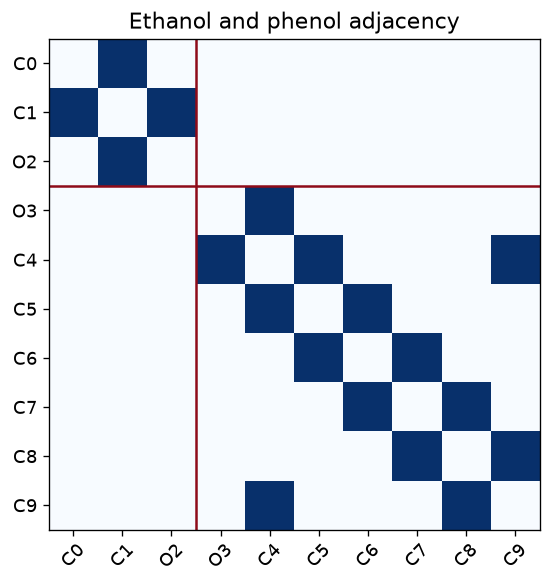

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(tf.sparse.to_dense(batch_a).numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(10), demo_labels, rotation=45)
ax.set_yticks(range(10), demo_labels)
ax.axvline(2.5, color=RED, linewidth=1.5)
ax.axhline(2.5, color=RED, linewidth=1.5)
ax.set_title('Ethanol and phenol adjacency')
plt.tight_layout()
plt.show()

## GNN Architecture Comparison

Both models embed atom features into 32 channels and perform three rounds of local updates. A global sum readout feeds a dense prediction head. The final linear output predicts standardized logS.

| Setting | GCN | Bond-aware MPNN |
| --- | --- | --- |
| Connectivity | Degree-normalized adjacency with self-loops | Binary adjacency |
| Bond features | Connectivity determines aggregation coefficients | Bond indicators enter each message |
| Local updates | Three GCN layers with separate parameters | Three rounds sharing message and GRU parameters |
| Readout | Global sum | Global sum |
| Prediction head | Dense layer, then scalar linear output | Dense layer, then scalar linear output |

In [16]:
WIDTH = 32
ROUNDS = 3
BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 12

### Graph Datasets

Each `Graph` stores the atom inputs, connectivity, and one standardized target. The GCN route uses `gcn_filter(A)`. The MPNN route pairs the binary adjacency entries with their bond features.

In [17]:
def graph_data(indices, kind):
    graphs = []
    for row in indices:
        x, a, e = featurize(mols[int(row)])
        y = np.array([(targets[int(row)] - train_mean) / train_sd], dtype=np.float32)
        if kind == 'gcn':
            graphs.append(Graph(x=x, a=gcn_filter(a), y=y))
        else:
            graphs.append(Graph(x=x, a=a, e=e, y=y))
    return GraphCollection(graphs)

data = {
    kind: {partition: graph_data(indices, kind) for partition, indices in split.items()}
    for kind in ['gcn', 'mpnn']
}

## GCN Architecture

The GCN update is

$$H'=\operatorname{ReLU}(SHW+b),\qquad S=\widetilde{D}^{-1/2}(A+I)\widetilde{D}^{-1/2}.$$

The normalized connectivity $S$ is computed once when the dataset is created. Within each GCN layer, the same feature-transformation matrix is shared across atoms and their neighbors.

In [18]:
from spektral.layers import GCNConv, MessagePassing, GlobalSumPool

## Bond-Aware MPNN

The MPNN constructs a message from the source atom state and the connecting bond features. A sum combines incoming messages at each receiving atom. A **gated recurrent unit**, or GRU, combines the incoming aggregate with the previous atom state.

$$m_i=\sum_{j\in\mathcal{N}(i)}\phi(h_j,e_{ji}),\qquad h_i'=\operatorname{GRU}(m_i,h_i).$$

The `BondMessages` layer uses Spektral's message-passing interface. Concatenation places the source atom state and bond indicators into one message input.

In [19]:
class BondMessages(MessagePassing):
    def __init__(self, channels, **kwargs):
        super().__init__(aggregate='sum', **kwargs)
        self.message_net = keras.layers.Dense(channels, activation='relu')

    def message(self, x, e=None):
        source = self.get_sources(x)
        message_input = tf.concat([source, e], axis=-1)
        return self.message_net(message_input)

### Keras Models

The model builder implements the two update rules. The MPNN reuses one message layer and one GRU across all rounds. `GlobalSumPool` groups atom states using the graph-ID vector.

In [20]:
def build_model(kind):
    x = keras.Input((F,), name='atom_features')
    a = keras.Input((None,), sparse=True, name='connectivity')
    graph_id = keras.Input((), dtype='int64', name='graph_id')
    h = keras.layers.Dense(WIDTH, activation='relu', name='atom_embedding')(x)
    if kind == 'gcn':
        for step in range(ROUNDS):
            h = GCNConv(WIDTH, activation='relu', name=f'gcn_{step}')([h, a])
        inputs = [x, a, graph_id]
    else:
        e = keras.Input((4,), name='bond_features')
        messages = BondMessages(WIDTH, name='bond_messages')
        update = keras.layers.GRUCell(WIDTH, name='atom_update')
        for step in range(ROUNDS):
            m = messages([h, a, e])
            h, _ = update(m, [h])
        inputs = [x, a, e, graph_id]
    g = GlobalSumPool(name='readout')([h, graph_id])
    g = keras.layers.Dense(WIDTH, activation='relu', name='head_hidden')(g)
    y = keras.layers.Dense(1, name='standardized_logS')(g)
    return keras.Model(inputs, y, name=kind)

Each run starts from a specified random seed. The parameter count describes the number of trainable values in the model.

In [21]:
import random

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

for kind in ['gcn', 'mpnn']:
    set_seed(29)
    preview_model = build_model(kind)
    print(kind.upper(), 'parameters', preview_model.count_params())

GCN parameters 4737
MPNN parameters 9089


## Training and Validation

Training minimizes **mean squared error**, or MSE, on standardized targets. Adam uses a learning rate of 0.001 and gradient-norm clipping at 5. Each mini-batch contains up to 32 molecules.

$$\mathcal{L}=\frac{1}{B}\sum_{b=1}^{B}(y_b-\widehat{y}_b)^2.$$

A gradient tape records the prediction calculation. Its gradients determine the optimizer's parameter update.

In [22]:
def make_train_step(model, optimizer):
    @tf.function(reduce_retracing=True)
    def train_step(inputs, y):
        with tf.GradientTape() as tape:
            prediction = model(inputs, training=True)
            loss = tf.reduce_mean(tf.square(y - prediction))
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        error = y - prediction
        return (
            tf.reduce_sum(tf.square(error)),
            tf.reduce_sum(tf.abs(error)),
            tf.size(y),
        )
    return train_step

### Validation Predictions

Validation evaluates the current parameters with `training=False`. The helper collects predictions and targets across all graph batches in their dataset order.

In [23]:
def evaluate(model, dataset):
    predictions, observed = [], []
    loader = DisjointLoader(dataset, batch_size=BATCH_SIZE, epochs=1, shuffle=False)
    for inputs, y in loader:
        predictions.append(model(inputs, training=False).numpy().ravel())
        observed.append(y.ravel())
    return np.concatenate(predictions), np.concatenate(observed)

### Training Loop

An **epoch** visits every training molecule once. The training order is shuffled at the start of each epoch. Validation MSE selects the best parameter values. Training stops after 12 epochs without improvement or after 80 epochs, and the best validation parameters are restored.

In [24]:
def fit_model(model, train, val, seed):
    optimizer = keras.optimizers.Adam(learning_rate=0.001, clipnorm=5.)
    train_step = make_train_step(model, optimizer)
    rng = np.random.default_rng(seed)
    best_loss = np.inf
    best_weights = None
    stale = 0
    history = []
    for epoch in range(MAX_EPOCHS):
        order = rng.permutation(len(train))
        loader = DisjointLoader(
            train[order], batch_size=BATCH_SIZE, epochs=1, shuffle=False
        )
        squared, absolute, count = 0., 0., 0
        for inputs, y in loader:
            batch_squared, batch_absolute, batch_count = train_step(inputs, y)
            squared += float(batch_squared)
            absolute += float(batch_absolute)
            count += int(batch_count)
        val_prediction, val_target = evaluate(model, val)
        val_loss = float(np.mean((val_prediction - val_target) ** 2))
        history.append({
            'epoch': epoch + 1,
            'train_mse': squared / count,
            'train_mae': absolute / count * train_sd,
            'val_mse': val_loss,
            'val_mae': float(np.mean(np.abs(val_prediction - val_target))) * train_sd,
        })
        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = model.get_weights()
            stale = 0
        else:
            stale += 1
        if epoch == 0 or (epoch + 1) % 20 == 0:
            print(f'{model.name.upper()} seed {seed} epoch {epoch + 1} '
                  f'validation MAE {history[-1]["val_mae"]:.3f}', flush=True)
        if stale >= PATIENCE:
            break
    model.set_weights(best_weights)
    return history

### Repeated Training Runs

Each architecture is trained with seeds 29, 30, and 31 on the same data partitions. The seed-29 models supply the individual-molecule predictions and explanations. Errors are calculated after predictions are transformed back to logS units.

In [25]:
run_rows = []
histories = {}
predictions = {}
explanation_models = {}
for kind in ['gcn', 'mpnn']:
    for seed in RUN_SEEDS:
        keras.backend.clear_session()
        set_seed(seed)
        model = build_model(kind)
        history = fit_model(model, data[kind]['train'], data[kind]['val'], seed)
        prediction, observed = evaluate(model, data[kind]['test'])
        prediction = prediction * train_sd + train_mean
        observed = observed * train_sd + train_mean
        mae = float(np.mean(np.abs(prediction - observed)))
        rmse = float(np.sqrt(np.mean((prediction - observed) ** 2)))
        run_rows.append([kind, seed, len(history), mae, rmse])
        histories[kind, seed] = history
        predictions[kind, seed] = (prediction, observed)
        if seed == 29:
            explanation_models[kind] = model
        print(f'{kind.upper()} seed {seed} test MAE {mae:.3f} RMSE {rmse:.3f}', flush=True)

GCN seed 29 epoch 1 validation MAE 1.833
GCN seed 29 epoch 20 validation MAE 0.724
GCN seed 29 epoch 40 validation MAE 0.677
GCN seed 29 epoch 60 validation MAE 0.576
GCN seed 29 test MAE 0.502 RMSE 0.684
GCN seed 30 epoch 1 validation MAE 1.663
GCN seed 30 epoch 20 validation MAE 0.699
GCN seed 30 epoch 40 validation MAE 0.584
GCN seed 30 epoch 60 validation MAE 0.536
GCN seed 30 test MAE 0.499 RMSE 0.668
GCN seed 31 epoch 1 validation MAE 1.567
GCN seed 31 epoch 20 validation MAE 0.768
GCN seed 31 epoch 40 validation MAE 0.620
GCN seed 31 epoch 60 validation MAE 0.605
GCN seed 31 test MAE 0.528 RMSE 0.715
MPNN seed 29 epoch 1 validation MAE 1.626
MPNN seed 29 epoch 20 validation MAE 0.789
MPNN seed 29 epoch 40 validation MAE 0.627
MPNN seed 29 test MAE 0.486 RMSE 0.662
MPNN seed 30 epoch 1 validation MAE 1.688
MPNN seed 30 epoch 20 validation MAE 0.855
MPNN seed 30 epoch 40 validation MAE 0.612
MPNN seed 30 epoch 60 validation MAE 0.548
MPNN seed 30 test MAE 0.488 RMSE 0.678
MPNN see

The learning curves report MAE in logS units. The dotted vertical line identifies the epoch selected using validation MSE.

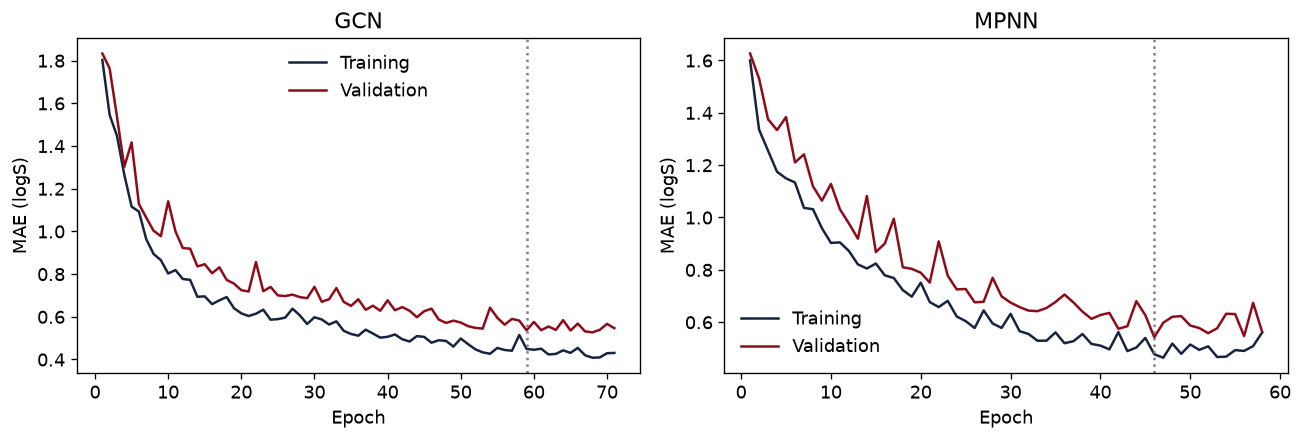

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, kind in zip(axes, ['gcn', 'mpnn']):
    history = histories[kind, 29]
    epochs = np.array([row['epoch'] for row in history])
    train_mae = np.array([row['train_mae'] for row in history])
    val_mae = np.array([row['val_mae'] for row in history])
    val_mse = np.array([row['val_mse'] for row in history])
    ax.plot(epochs, train_mae, color=NAVY, label='Training')
    ax.plot(epochs, val_mae, color=RED, label='Validation')
    ax.axvline(epochs[np.argmin(val_mse)], color='gray', linestyle=':')
    ax.set(title=kind.upper(), xlabel='Epoch', ylabel='MAE (logS)')
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Model Performance Comparison

**MAE** averages the absolute prediction errors. **RMSE** takes the square root of the mean squared error and gives greater weight to large errors. Both are expressed in logS units.

The table reports the mean and sample standard deviation across the three training seeds on the fixed test partition.

In [27]:
print(f'{"Model":<12} {"Test MAE":>20} {"Test RMSE":>20}')
for kind in ['gcn', 'mpnn']:
    values = np.array([[row[3], row[4]] for row in run_rows if row[0] == kind])
    mean = values.mean(axis=0)
    sd = values.std(axis=0, ddof=1)
    mae_text = f'{mean[0]:.3f} +/- {sd[0]:.3f}'
    rmse_text = f'{mean[1]:.3f} +/- {sd[1]:.3f}'
    print(f'{kind.upper():<12} {mae_text:>20} {rmse_text:>20}')

Model                    Test MAE            Test RMSE
GCN               0.510 +/- 0.016      0.689 +/- 0.024
MPNN              0.502 +/- 0.026      0.679 +/- 0.016


The prediction plots compare the seed-29 test predictions with measured logS. The diagonal represents exact agreement. Points above it have predicted solubility greater than the measured value.

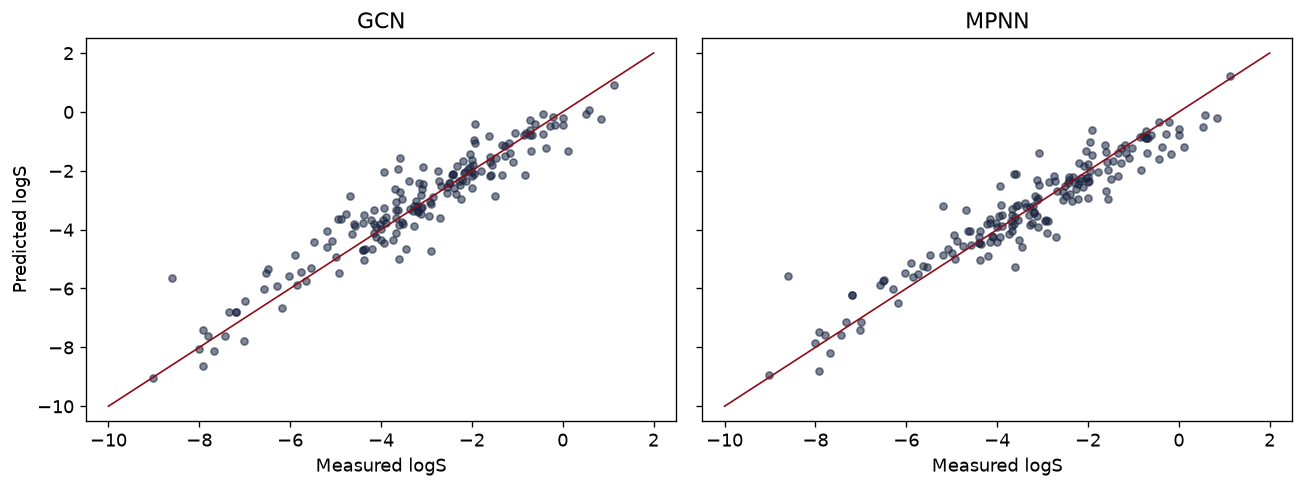

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, kind in zip(axes, ['gcn', 'mpnn']):
    prediction, observed = predictions[kind, 29]
    ax.scatter(observed, prediction, color=NAVY, s=18, alpha=0.55)
    ax.plot([-10, 2], [-10, 2], color=RED, linewidth=1)
    ax.set(title=kind.upper(), xlabel='Measured logS', xlim=(-10.5, 2.5), ylim=(-10.5, 2.5))
axes[0].set_ylabel('Predicted logS')
plt.tight_layout()
plt.show()

## Individual Molecule Prediction

The selected test molecule is p-bromoacetanilide. Its prediction follows the same graph representation and target transformation used for the test set.

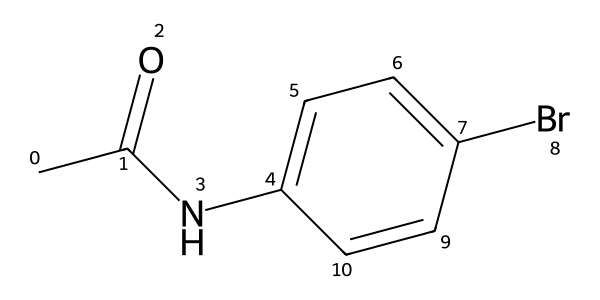

In [29]:
from rdkit.Chem import Draw

draw_options = Draw.MolDrawOptions()
draw_options.useBWAtomPalette()
draw_options.addAtomIndices = True
Draw.MolToImage(example_mol, size=(600, 300), options=draw_options)

The helper prepares one molecular graph and returns its prediction in logS units. The GCN receives normalized connectivity, and the MPNN receives binary connectivity with bond features.

In [30]:
def predict_one(model, mol, kind, x_override=None):
    x, a, e = featurize(mol)
    if x_override is not None:
        x = np.asarray(x_override, dtype=np.float32)
    adjacency = gcn_filter(a) if kind == 'gcn' else a
    adjacency = tf.sparse.from_dense(adjacency.toarray())
    graph_ids = tf.zeros(len(x), dtype=tf.int64)
    if kind == 'gcn':
        inputs = [x, adjacency, graph_ids]
    else:
        inputs = [x, adjacency, e, graph_ids]
    output = model(inputs, training=False)[0, 0]
    return float(output) * train_sd + train_mean

print(f'Measured logS {targets[example_row]:.3f}')
for kind in ['gcn', 'mpnn']:
    value = predict_one(explanation_models[kind], example_mol, kind)
    print(f'{kind.upper()} prediction {value:.3f}')

Measured logS -3.083
GCN prediction -2.455
MPNN prediction -2.487


## Attribution Baseline

A **baseline** defines the input against which an attribution is measured. Here, the reference sets all atom features to zero. Graph connectivity $A$ and bond features $E$ remain fixed throughout the explanation.

The difference between the actual-input prediction and the reference prediction is the quantity allocated to the atom features.

In [31]:
mpnn = explanation_models['mpnn']
zero_features = np.zeros_like(x_case)
case_prediction = predict_one(mpnn, example_mol, 'mpnn')
baseline_prediction = predict_one(mpnn, example_mol, 'mpnn', x_override=zero_features)
prediction_difference = case_prediction - baseline_prediction
print(f'Reference prediction {baseline_prediction:.4f}')
print(f'Actual-input prediction {case_prediction:.4f}')
print(f'Prediction difference {prediction_difference:.4f}')

Reference prediction -2.0664
Actual-input prediction -2.4874
Prediction difference -0.4211


The interpolation parameter $\alpha$ controls the position along the feature path,

$$X(\alpha)=X^0+\alpha(X-X^0).$$

At the start, the input equals the reference features. At the end, it equals the molecule's actual features.

In [32]:
print(f'{"Fraction of input":<20} {"Predicted logS":>16}')
for alpha in np.linspace(0, 1, 5):
    features = zero_features + alpha * (x_case - zero_features)
    value = predict_one(mpnn, example_mol, 'mpnn', x_override=features)
    print(f'{alpha:<20.2f} {value:>16.4f}')

Fraction of input      Predicted logS
0.00                          -2.0664
0.25                          -1.5284
0.50                          -1.6181
0.75                          -2.0129
1.00                          -2.4874


## Feature Attribution Methods

**Integrated gradients** measures how much each atom feature contributes to the prediction difference between a reference input and the molecule. It averages the feature's prediction sensitivity along the reference-to-input path and multiplies it by the feature's total change,

$$\mathrm{IG}_{ik}=(X_{ik}-X^0_{ik})\int_0^1
\frac{\partial f(X^0+\alpha(X-X^0),A,E)}{\partial X_{ik}}\,d\alpha.$$

The index $i$ identifies an atom, and $k$ identifies one of its features. $X^0$ contains the reference features, and $X$ contains the molecule's actual features. As $\alpha$ increases, the gradient measures prediction sensitivity at successive points along this path. Graph connectivity $A$ and bond features $E$ stay fixed.

The signed feature contributions sum to the prediction difference,

$$\sum_{i,k}\mathrm{IG}_{ik}=f(X,A,E)-f(X^0,A,E).$$

## Integrated Gradients Calculation

### One-Feature Example

For $f(x)=x^2$, the derivative is $2x$. A path from 0 to 1 has gradients 0, 1, and 2 at the three points below. Trapezoidal integration weights the endpoints by one half.

In [33]:
toy_x = np.array([0., 0.5, 1.])
toy_gradients = 2 * toy_x
weights = np.array([0.5, 1., 0.5])
mean_gradient = np.sum(weights * toy_gradients) / 2
toy_ig = (toy_x[-1] - toy_x[0]) * mean_gradient
print('Path points', toy_x)
print('Gradients', toy_gradients)
print(f'Average gradient {mean_gradient:.1f}')
print(f'Integrated gradient {toy_ig:.1f}')
print(f'Prediction difference {toy_x[-1] ** 2 - toy_x[0] ** 2:.1f}')

Path points [0.  0.5 1. ]
Gradients [0. 1. 2.]
Average gradient 1.0
Integrated gradient 1.0
Prediction difference 1.0


### Molecular Feature Integration

The molecular calculation divides the path into 512 intervals. The gradient is evaluated at each interval boundary. The endpoint weights implement the trapezoidal rule for every atom-feature entry.

A gradient tape watches the features at each path point and differentiates the prediction in logS units.

In [34]:
case_adjacency = tf.sparse.from_dense(a_case.toarray())
case_bonds = tf.convert_to_tensor(e_case, dtype=tf.float32)
case_graph_ids = tf.zeros(len(x_case), dtype=tf.int64)

@tf.function
def input_gradients(features):
    with tf.GradientTape(watch_accessed_variables=False) as tape:
        tape.watch(features)
        scaled_output = mpnn([features, case_adjacency, case_bonds, case_graph_ids], training=False)[0, 0]
        output = scaled_output * train_sd + train_mean
    return tape.gradient(output, features)

def integrated_gradients(features, reference, steps=512):
    features = tf.convert_to_tensor(features, dtype=tf.float32)
    reference = tf.convert_to_tensor(reference, dtype=tf.float32)
    total_gradient = tf.zeros_like(features)
    for step in range(steps + 1):
        alpha = step / steps
        path_features = reference + alpha * (features - reference)
        weight = 0.5 if step in (0, steps) else 1.
        total_gradient += weight * input_gradients(path_features)
    average_gradient = total_gradient / steps
    return ((features - reference) * average_gradient).numpy()

ig = integrated_gradients(x_case, zero_features, steps=512)
print('Attribution shape', ig.shape)

Attribution shape (11, 14)


The **integration residual** measures the numerical difference between the summed feature contributions and the prediction difference. Its magnitude describes the accuracy of the numerical integration.

In [35]:
ig_sum = float(ig.sum())
integration_residual = prediction_difference - ig_sum
print(f'Prediction difference {prediction_difference:.4f}')
print(f'Sum of feature IG {ig_sum:.4f}')
print(f'Absolute integration residual {abs(integration_residual):.4f}')

Prediction difference -0.4211
Sum of feature IG -0.4221
Absolute integration residual 0.0010


## Atom Attribution Map

An atom's signed contribution is the sum of its feature contributions,

$$\mathrm{AtomIG}_i=\sum_k\mathrm{IG}_{ik}.$$

Blue indicates a positive contribution to the prediction relative to the reference. Red indicates a negative contribution.

In [36]:
atom_signed = ig.sum(axis=1)
print(f'{"Atom":<8} {"Signed IG":>14}')
for atom, tag in enumerate(atom_tags):
    print(f'{tag:<8} {atom_signed[atom]:>14.3f}')

Atom          Signed IG
C0                0.406
C1               -0.403
O2                0.645
N3                0.517
C4               -0.374
C5               -0.154
C6               -0.130
C7               -0.287
Br8              -0.357
C9               -0.130
C10              -0.154


The molecular drawing places each computed contribution on the corresponding atom. A common color scale links the atom colors to signed values.

In [37]:
import io
from PIL import Image
from rdkit.Chem.Draw import rdMolDraw2D
from matplotlib.colors import LinearSegmentedColormap, Normalize

atom_cmap = LinearSegmentedColormap.from_list(
    'atom_attribution', plt.get_cmap('RdBu')(np.linspace(0.15, 0.85, 256))
)

def atom_map(mol, values, limit):
    drawer = rdMolDraw2D.MolDraw2DCairo(1000, 550)
    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.padding = 0.12
    options.bondLineWidth = 3
    options.fixedFontSize = 27
    for atom in mol.GetAtoms():
        options.atomLabels[atom.GetIdx()] = atom.GetSymbol() + str(atom.GetIdx())
    norm = Normalize(vmin=-limit, vmax=limit)
    colors = {index: tuple(atom_cmap(norm(value))[:3]) for index, value in enumerate(values)}
    rdMolDraw2D.PrepareAndDrawMolecule(
        drawer, mol, highlightAtoms=list(range(len(values))), highlightBonds=[],
        highlightAtomColors=colors,
        highlightAtomRadii={index: 0.32 for index in range(len(values))},
    )
    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))

The map displays the seed-29 MPNN explanation with a zero-feature reference.

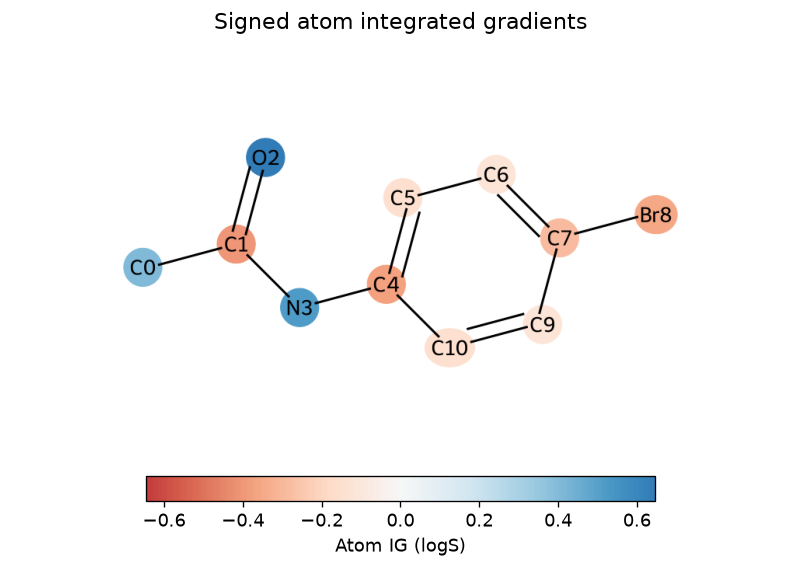

In [38]:
limit = float(np.max(np.abs(atom_signed)))
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(atom_map(example_mol, atom_signed, limit))
ax.set_axis_off()
ax.set_title('Signed atom integrated gradients')
colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=Normalize(-limit, limit), cmap=atom_cmap),
    ax=ax, orientation='horizontal', fraction=0.055, pad=0.02,
)
colorbar.set_label('Atom IG (logS)')
plt.show()

The amide N-H group can donate a hydrogen bond to water, and the carbonyl oxygen can accept one. The aromatic ring and bromine contribute nonpolar surface. These functional groups provide chemical context for interpreting the molecular pattern.

## Atom Feature Contributions

Individual features at one atom can have contributions of opposite sign. The N3 example separates its nitrogen indicator, scaled degree, and scaled hydrogen count. Their signed sum gives N3's atom attribution.

In [39]:
nitrogen_index = next(atom.GetIdx() for atom in example_mol.GetAtoms() if atom.GetSymbol() == 'N')
selected_features = [ELEMENTS.index('N'), FEATURES.index('Degree / 4'), FEATURES.index('H count / 4')]
print('Atom', atom_tags[nitrogen_index])
print(f'{"Feature":<20} {"Input value":>14} {"Signed IG":>14}')
for feature in selected_features:
    print(f'{FEATURES[feature]:<20} {x_case[nitrogen_index, feature]:>14.3f} '
          f'{ig[nitrogen_index, feature]:>14.3f}')
print(f'Atom signed sum {atom_signed[nitrogen_index]:.3f}')

Atom N3
Feature                 Input value      Signed IG
Is N                          1.000          0.689
Degree / 4                    0.500         -0.350
H count / 4                   0.250          0.178
Atom signed sum 0.517


The bar directions show which feature contributions increase or decrease the prediction relative to the reference.

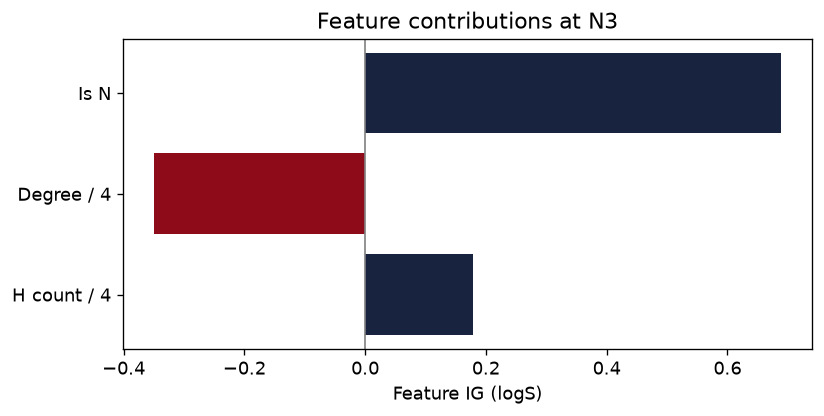

In [40]:
feature_values = ig[nitrogen_index, selected_features]
feature_labels = [FEATURES[index] for index in selected_features]
bar_colors = [NAVY if value >= 0 else RED for value in feature_values]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(feature_labels, feature_values, color=bar_colors)
ax.axvline(0, color='gray', linewidth=1)
ax.invert_yaxis()
ax.set(title='Feature contributions at ' + atom_tags[nitrogen_index], xlabel='Feature IG (logS)')
plt.tight_layout()
plt.show()

## Chemical Plausibility Check

**Crippen atom contributions** are terms in an empirical logP descriptor of molecular hydrophobicity. Negating those terms gives a hydrophilicity-oriented comparison with the signed solubility attributions. The comparison examines qualitative sign agreement.

In [41]:
from rdkit.Chem import rdMolDescriptors

crippen_values = rdMolDescriptors._CalcCrippenContribs(example_mol)
negative_crippen = -np.array([values[0] for values in crippen_values])
same_sign = np.sign(atom_signed) == np.sign(negative_crippen)
print(f'{"Atom":<8} {"Signed IG":>14} {"Negative Crippen":>20} {"Same sign":>12}')
for atom, tag in enumerate(atom_tags):
    agreement = 'Yes' if same_sign[atom] else 'No'
    print(f'{tag:<8} {atom_signed[atom]:>14.3f} {negative_crippen[atom]:>20.3f} {agreement:>12}')
print('Same-sign atoms', int(same_sign.sum()), 'of', len(same_sign))

Atom          Signed IG     Negative Crippen    Same sign
C0                0.406               -0.144           No
C1               -0.403                0.278           No
O2                0.645                0.153          Yes
N3                0.517                0.519          Yes
C4               -0.374               -0.462          Yes
C5               -0.154               -0.158          Yes
C6               -0.130               -0.158          Yes
C7               -0.287               -0.198          Yes
Br8              -0.357               -0.846          Yes
C9               -0.130               -0.158          Yes
C10              -0.154               -0.158          Yes
Same-sign atoms 9 of 11


The two maps use the same color direction. Positive values are blue, and negative values are red. The labels distinguish the model's logS attribution from the empirical logP terms.

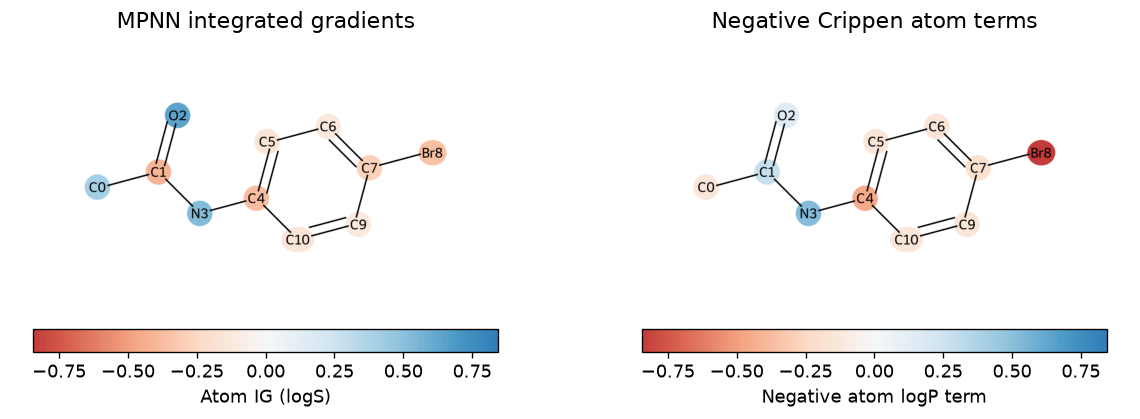

In [42]:
common_limit = float(max(np.max(np.abs(atom_signed)), np.max(np.abs(negative_crippen))))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, values, title, units in zip(
    axes,
    [atom_signed, negative_crippen],
    ['MPNN integrated gradients', 'Negative Crippen atom terms'],
    ['Atom IG (logS)', 'Negative atom logP term'],
):
    ax.imshow(atom_map(example_mol, values, common_limit))
    ax.set_axis_off()
    ax.set_title(title)
    colorbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=Normalize(-common_limit, common_limit), cmap=atom_cmap),
        ax=ax, orientation='horizontal', fraction=0.06, pad=0.03,
    )
    colorbar.set_label(units)
plt.show()